# Genetic perturbation signatures across signaling contexts

This analysis compares processed effects from the Arc Institute PIE redistribution of Jiang et al. signaling Perturb-seq. It examines A549 under IFN-beta and IFN-gamma. It is a descriptive reanalysis of single-cell-derived summaries, **not a raw-cell or replicate-aware DE analysis**. Neither context is a terpene exposure.

The source card specifies CP10k normalization, ≥5 CPM gene filtering and cell-level Mann–Whitney tests. We do not use its p-values for population-level inference. Source revision and byte checksums are frozen in `data/jiang/sources.json`. Shared gene coverage is explicitly joined; missing tests are not zero effects.


In [ ]:
from pathlib import Path
import os, urllib.request

if Path('/content').exists():
    candidates = [Path.cwd(), Path('/content/terputer-terpene-exposure'), Path('/content/terpene-transcriptomics')]
    project = next((p for p in candidates if (p / 'results/gse136998/run_manifest.json').exists() and (p / 'data/jiang/sources.json').exists()), None)
    if project is None:
        project = Path('/content/terputer-terpene-exposure')
        site = 'https://terpedia.github.io/research/terpene-transcriptomics/'
        files = ['results/gse136998/GSE136998_rsem.genes.fpkm.table.txt.gz', 'results/gse136998/run_manifest.json', 'data/jiang/sources.json', 'data/jiang/README.md', 'data/jiang/a549_ifnb.parquet', 'data/jiang/a549_ifng.parquet']
        for name in files:
            local = project / name
            local.parent.mkdir(parents=True, exist_ok=True)
            if not local.exists(): urllib.request.urlretrieve(site + name, local)
    (project / 'notebooks').mkdir(exist_ok=True)
    os.chdir(project / 'notebooks')


In [1]:
from pathlib import Path
import hashlib, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
cwd = Path.cwd()
PROJECT = cwd if (cwd / 'data' / 'jiang').exists() else cwd.parent
DATA = PROJECT / 'data' / 'jiang'
OUT = PROJECT / 'results' / 'jiang'
OUT.mkdir(parents=True, exist_ok=True)
manifest = json.loads((DATA / 'sources.json').read_text())
for record in manifest['files']:
    assert hashlib.sha256((DATA / record['file']).read_bytes()).hexdigest() == record['sha256']
a = pd.read_parquet(DATA / 'a549_ifnb.parquet')
b = pd.read_parquet(DATA / 'a549_ifng.parquet')
for frame in [a,b]:
    assert not frame.duplicated(['target','feature']).any()
print('Source revision:', manifest['revision'])
print('Rows:', len(a), len(b))
print('Shared perturbed genes:', sorted(set(a.target) & set(b.target)))


Source revision: d0519f67452a0662c2db30c3831900b38aa3c017
Rows: 185185 173859


Shared perturbed genes: ['BATF2', 'PARP12']


## Analysis rule

For each shared perturbation, join on measured gene and retain finite log fold changes with reference mean ≥1 in both contexts. This transparent expression filter reduces domination by unstable low-abundance ratios; it is a descriptive sensitivity choice, not an inferential QC threshold. Calculate Spearman rank correlation, sign agreement, and the median absolute difference. Correlation measures signature similarity and does not test an interaction. Both contexts use their own stimulated non-targeting controls, so differences reflect context-associated perturbation effects, not direct cytokine treatment effects.


,target,shared_tested_features,features_after_filter,spearman,sign_agreement,median_abs_difference,cells_ifnb,cells_ifng
0,BATF2,11574,2014,0.069027,0.522840,0.097088,605,522
1,PARP12,11579,2014,0.038067,0.514896,0.100983,550,619


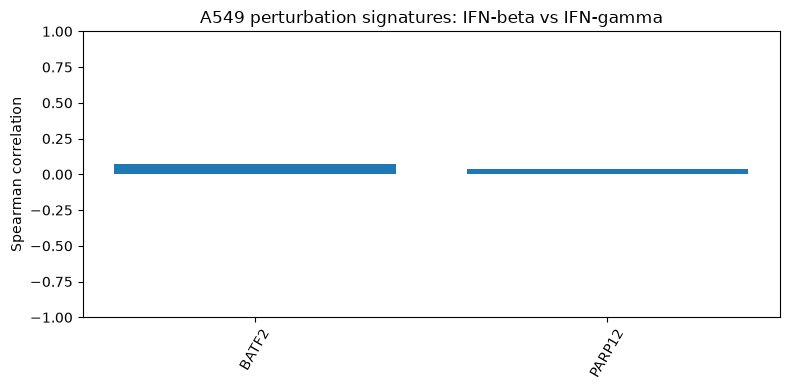

In [2]:
joined = a.merge(b, on=['target','feature'], suffixes=('_ifnb','_ifng'), validate='one_to_one')
records=[]
for target, frame in joined.groupby('target'):
    x=frame.loc[(frame.ref_mean_ifnb >= 1) & (frame.ref_mean_ifng >= 1)].copy()
    x=x.loc[np.isfinite(x.log2_fold_change_ifnb) & np.isfinite(x.log2_fold_change_ifng)]
    v=x.log2_fold_change_ifnb; w=x.log2_fold_change_ifng
    records.append({'target':target,'shared_tested_features':len(frame),'features_after_filter':len(x),
                    'spearman':v.rank().corr(w.rank()),
                    'sign_agreement':(np.sign(v)==np.sign(w)).mean(),
                    'median_abs_difference':(v-w).abs().median(),
                    'cells_ifnb':int(frame.target_ncells_ifnb.iloc[0]),
                    'cells_ifng':int(frame.target_ncells_ifng.iloc[0])})
summary=pd.DataFrame(records).sort_values('target')
display(summary)
summary.to_csv(OUT / 'a549_context_comparison.tsv', sep='\t',index=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(summary.target,summary.spearman)
ax.set(ylabel='Spearman correlation',title='A549 perturbation signatures: IFN-beta vs IFN-gamma',ylim=(-1,1))
ax.tick_params(axis='x',rotation=60)
fig.tight_layout();fig.savefig(OUT / 'context_similarity.png',dpi=180)
plt.show()


## Interpretation and limitations

Similarity can identify shared response programs, and discordance can prioritize context-specific hypotheses. These summaries cannot establish replicated biological interactions: donor/culture and guide assignments are absent from the processed tables. Shared controls induce dependence across perturbation comparisons. Cell counts are coverage measures, not independent donor counts. Filtering changes the measured gene universe and must accompany any comparison.

A full reanalysis should recover raw-cell counts, guides, experimental batches, independent cultures/donors and perturbation efficacy, then estimate replicated context interactions. The present analysis demonstrates explicit joins, source verification and bounded interpretation of processed Perturb-seq effects. It provides no evidence for terpene targets or installed human variant effects.
